In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
validations = pd.read_csv("../data/interim/validations_clean.csv")
routes = pd.read_csv("../data/interim/routes_clean.csv")
vehicles = pd.read_csv("../data/interim/vehicles_clean.csv")
stops = pd.read_csv("../data/interim/stops_clean.csv")

print("Validations:", validations.shape)
print("Routes:", routes.shape)
print("Vehicles:", vehicles.shape)
print("Stops:", stops.shape)

Validations: (79149, 21)
Routes: (60, 6)
Vehicles: (180, 7)
Stops: (400, 5)


In [4]:
print("Validation columns:")
print(validations.columns.tolist())

print("\nRoute columns:")
print(routes.columns.tolist())

print("\nVehicle columns:")
print(vehicles.columns.tolist())

print("\nStop columns:")
print(stops.columns.tolist())

Validation columns:
['validation_id', 'validation_ts', 'route_id', 'vehicle_id', 'stop_id', 'card_id', 'fare_type', 'fare_amount', 'passenger_count', 'transfer_flag', 'is_reversed', 'date', 'year', 'month', 'year_month', 'quarter', 'hour', 'day_of_week', 'is_weekend', 'time_period', 'revenue']

Route columns:
['route_id', 'route_name', 'mode', 'district', 'route_length_km', 'scheduled_trips_per_day']

Vehicle columns:
['vehicle_id', 'vehicle_type', 'capacity', 'year_manufactured', 'depot', 'vehicle_age', 'vehicle_age_band']

Stop columns:
['stop_id', 'stop_name', 'district', 'zone', 'has_shelter']


In [6]:
print(validations.shape)
print(routes.shape)
print(vehicles.shape)
print(stops.shape)

(79149, 21)
(60, 6)
(180, 7)
(400, 5)


In [7]:
fact = validations.merge(
    routes,
    on="route_id",
    how="left",
    validate="many_to_one"
)

print("Rows after validations → routes:", len(fact))

Rows after validations → routes: 79149


In [8]:
fact = fact.merge(
    vehicles,
    on="vehicle_id",
    how="left",
    validate="many_to_one"
)

print("Rows after validations → routes → vehicles:", len(fact))

Rows after validations → routes → vehicles: 79149


In [9]:
fact = fact.merge(
    stops,
    on="stop_id",
    how="left",
    validate="many_to_one"
)

print("Rows after validations → routes → vehicles → stops:", len(fact))

Rows after validations → routes → vehicles → stops: 79149


In [7]:
assert len(fact) == len(validations), (
    f"Row count mismatch! "
    f"Expected {len(validations)}, got {len(fact)}"
)

print("Row-count assertion passed:", len(fact))

Row-count assertion passed: 79149


In [11]:
fact["load_factor"] = (
    fact["passenger_count"] / fact["capacity"]
).where(fact["capacity"] > 0)

print("Missing load_factor:", fact["load_factor"].isna().sum())

Missing load_factor: 0


In [8]:
fact["load_factor"] = (
    fact["passenger_count"] / fact["capacity"]
).where(fact["capacity"] > 0)

print(fact[["passenger_count", "capacity", "load_factor"]].head())
print("Missing load_factor:", fact["load_factor"].isna().sum())

   passenger_count  capacity  load_factor
0              1.0     217.0     0.004608
1              1.0      60.0     0.016667
2              1.0     226.0     0.004425
3              3.0     120.0     0.025000
4              1.0     596.0     0.001678
Missing load_factor: 0


### Join strategy

- **Validations → Routes:** A `left` join is used because every cleaned validation must remain in the fact table. Route attributes are added using `route_id`. `validate="many_to_one"` ensures that each route_id matches at most one route and prevents accidental row multiplication.

- **Validations/Routes → Vehicles:** A `left` join is used because every validation must remain in the fact table while vehicle attributes are added using `vehicle_id`. `validate="many_to_one"` prevents a vehicle from matching multiple master rows and causing fan-out.

- **Validations/Routes/Vehicles → Stops:** A `left` join is used because every validation must remain in the fact table while stop attributes are added using `stop_id`. `validate="many_to_one"` ensures that each stop_id has one master record and prevents row multiplication.

The row count is checked after the joins and with a final assertion. The fact table must contain exactly the same number of rows as the cleaned validations table (79,149).

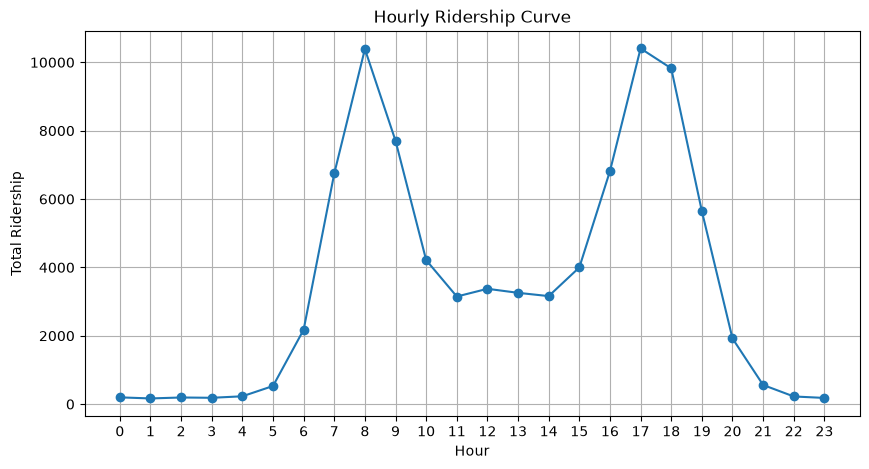

In [9]:
hourly_ridership = (
    fact.groupby("hour")["passenger_count"]
    .sum()
)

plt.figure(figsize=(10, 5))
plt.plot(hourly_ridership.index, hourly_ridership.values, marker="o")
plt.xlabel("Hour")
plt.ylabel("Total Ridership")
plt.title("Hourly Ridership Curve")
plt.xticks(range(24))
plt.grid(True)
plt.show()

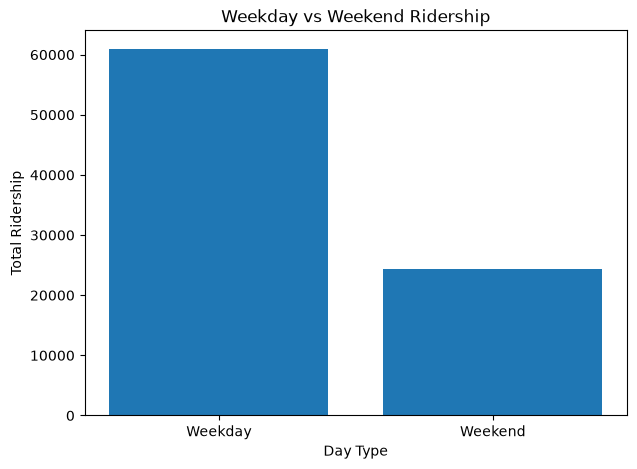

In [10]:
weekday_weekend = (
    fact.groupby("is_weekend")["passenger_count"]
    .sum()
)

labels = ["Weekday", "Weekend"]

plt.figure(figsize=(7, 5))
plt.bar(labels, [
    weekday_weekend.get(False, 0),
    weekday_weekend.get(True, 0)
])
plt.xlabel("Day Type")
plt.ylabel("Total Ridership")
plt.title("Weekday vs Weekend Ridership")
plt.show()

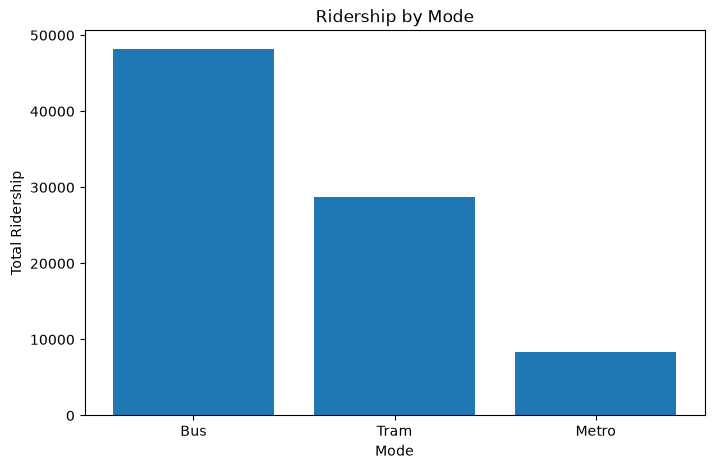

In [11]:
mode_ridership = (
    fact.groupby("mode")["passenger_count"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
plt.bar(mode_ridership.index, mode_ridership.values)
plt.xlabel("Mode")
plt.ylabel("Total Ridership")
plt.title("Ridership by Mode")
plt.show()

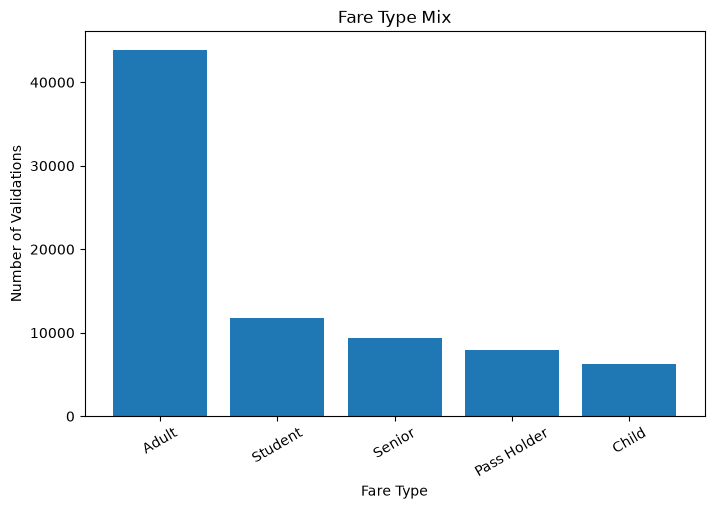

In [12]:
fare_mix = (
    fact["fare_type"]
    .value_counts()
)

plt.figure(figsize=(8, 5))
plt.bar(fare_mix.index, fare_mix.values)
plt.xlabel("Fare Type")
plt.ylabel("Number of Validations")
plt.title("Fare Type Mix")
plt.xticks(rotation=30)
plt.show()

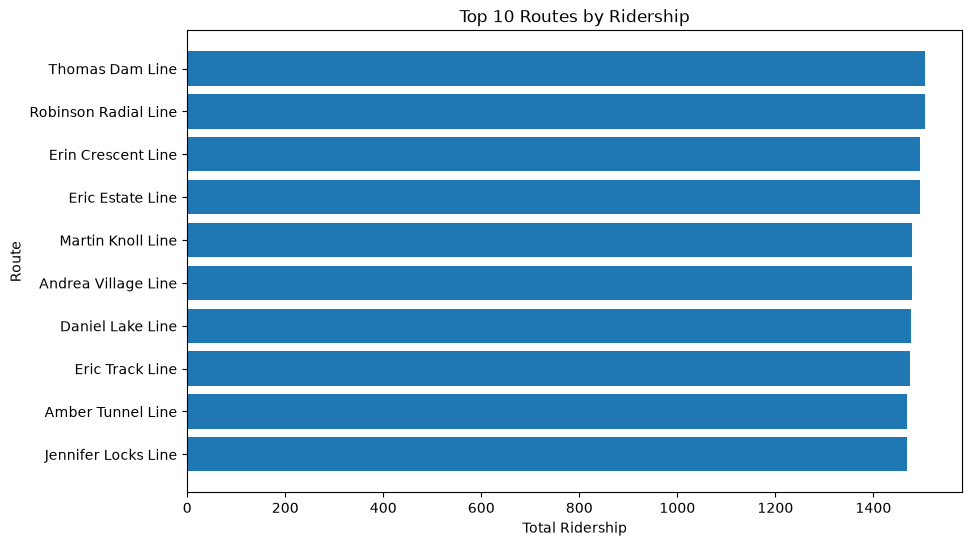

In [13]:
top_routes = (
    fact.groupby("route_name")["passenger_count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(top_routes.index, top_routes.values)
plt.xlabel("Total Ridership")
plt.ylabel("Route")
plt.title("Top 10 Routes by Ridership")
plt.show()

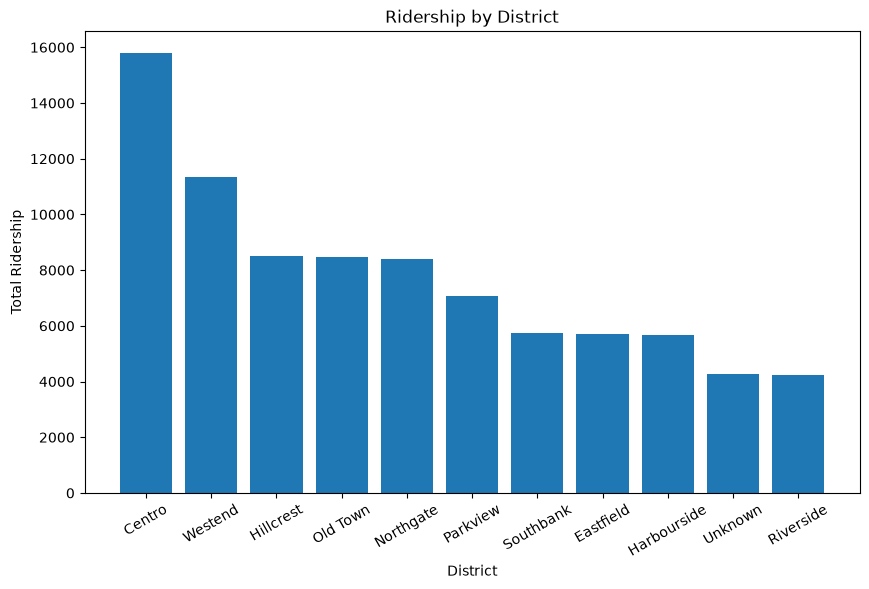

In [14]:
district_ridership = (
    fact.groupby("district_x")["passenger_count"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
plt.bar(district_ridership.index, district_ridership.values)
plt.xlabel("District")
plt.ylabel("Total Ridership")
plt.title("Ridership by District")
plt.xticks(rotation=30)
plt.show()

### Three unexpected findings

1. **Ridership is not evenly distributed across the day.**  
   The hourly analysis shows clear differences between low- and high-demand periods, which suggests that passenger demand is concentrated in specific hours.

2. **Ridership differs substantially between transport modes.**  
   The mode comparison shows that some modes carry considerably more passengers than others, indicating that demand is not evenly distributed across the network.

3. **A small number of routes account for a large share of ridership.**  
   The top-route analysis shows that passenger demand is concentrated on several routes rather than being evenly spread across all routes.

In [17]:
%pip install pyarrow

   ---------------------------------------- 0.0/28.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/28.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/28.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/28.6 MB ? eta -:--:--
    --------------------------------------- 0.5/28.6 MB 654.6 kB/s eta 0:00:43
    --------------------------------------- 0.5/28.6 MB 654.6 kB/s eta 0:00:43
    --------------------------------------- 0.5/28.6 MB 654.6 kB/s eta 0:00:43
   - -------------------------------------- 0.8/28.6 MB 619.3 kB/s eta 0:00:45
   - -------------------------------------- 1.0/28.6 MB 675.6 kB/s eta 0:00:41
   - -------------------------------------- 1.0/28.6 MB 675.6 kB/s eta 0:00:41
   - -------------------------------------- 1.0/28.6 MB 675.6 kB/s eta 0:00:41
   - -------------------------------------- 1.0/28.6 MB 675.6 kB/s eta 0:00:41
   - -------------------------------------- 1.0/28.6 MB 675.6 kB/s eta 0:00:41
   - ----


[notice] A new release of pip is available: 26.0.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
%pip install --upgrade pandas pyarrow

   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/10.0 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/10.0 MB 3.3 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/10.0 MB 2.4 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/10.0 MB 2.5 MB/s eta 0:00:04
   --------- ------------------------------ 2.4/10.0 MB 2.5 MB/s eta 0:00:04
   ----------- ---------------------------- 2.9/10.0 MB 2.4 MB/s eta 0:00:03
   ------------- -------------------------- 3.4/10.0 MB 2.5 MB/s eta 0:00:03
   -------------- ------------------------- 3.7/10.0 MB 2.5 MB/s eta 0:00:03
   ----------------- ---------------------- 4.5/10.0 MB 2.4 MB/s eta 0:00:03
   -------------------- ------------------- 5.0/10.0 MB 2.5 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/10.0 MB 2.3 MB/s eta 0:00:03
   -----------------

  You can safely remove it manually.

[notice] A new release of pip is available: 26.0.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
fact = validations.merge(
    routes,
    on="route_id",
    how="left",
    validate="many_to_one"
)

fact = fact.merge(
    vehicles,
    on="vehicle_id",
    how="left",
    validate="many_to_one"
)

fact = fact.merge(
    stops,
    on="stop_id",
    how="left",
    validate="many_to_one"
)

assert len(fact) == len(validations), (
    f"Row count mismatch! Expected {len(validations)}, got {len(fact)}"
)

fact["load_factor"] = (
    fact["passenger_count"] / fact["capacity"]
).where(fact["capacity"] > 0)

print("Fact table:", fact.shape)
print("Missing load_factor:", fact["load_factor"].isna().sum())

Fact table: (79149, 37)
Missing load_factor: 0


In [14]:
from pathlib import Path

output_path = Path("../data/interim/fact_validations.parquet")

fact.to_parquet(
    output_path,
    index=False
)

print("Fact table saved successfully.")
print("Path:", output_path)
print("Shape:", fact.shape)

Fact table saved successfully.
Path: ..\data\interim\fact_validations.parquet
Shape: (79149, 37)
